# Charge transition level (CTL) plots — `plot_ctl`

`plot_ctl` draws a formation energy vs Fermi energy diagram for each defect, using a single (usually crystalline) host cell.

For every defect it:
- plots one line per charge state, solid where that charge state is the most stable and dashed elsewhere,
- marks each thermodynamic transition level with a dot and a dotted vertical guide,
- shades the valence band (green, left) and conduction band (orange, right).

This notebook covers:
1. Describing defects with the `Defect` dataclass
2. Making the plots
3. Reading the computed transition levels
4. Changing the look with `StyleOptions`
5. Loading defects from a CSV file

In [1]:
from cp2k_utils.ctl import Defect, StyleOptions, plot_ctl, load_defects_csv, write_sample_csv

## 1. Input data

Each charge state of each defect is one `Defect`:

| field | meaning | units |
|---|---|---|
| `name` | species added/removed, e.g. `'N'`, `'O'`, `'N2'` | |
| `charge` | charge state of the cell | e |
| `energy` | total energy of the defective cell | **Ha** |
| `mu_added` | chemical potential of the species added (0 for a vacancy) | **Ha** |
| `correction` | finite-size charge correction | **eV** |
| `defect_type` | `'i'` interstitial, `'v'` vacancy, `'s'` substitution | |
| `site` | site label (e.g. which O was replaced/removed); `''` if not needed | |
| `mu_removed` | chemical potential of the species removed (0 for an interstitial) | **Ha** |
| `label` | ID used to group charge states into one defect, and in output file names | |
| `title` *(optional)* | LaTeX label to use on plots instead of the auto-generated one | |

You also need the pristine host's total energy, VBM and CBM (all in **Ha**).

The formation energy is

$$E_f(E_F) = E_\mathrm{defect} - E_\mathrm{bulk} - \mu_\mathrm{added} + \mu_\mathrm{removed} + E_\mathrm{corr} + q\,(E_\mathrm{VBM} + E_F)$$

The data below are N interstitials and O vacancies in crystalline HfO$_2$.

In [2]:
# chemical potentials (Ha) - half the energy of the N2 / O2 molecule
N = -19.82216306984949 / 2
O = -31.80451126833290 / 2

defects = [
    # N interstitial
    Defect('N',  3, -2615.48791233421616, N, 0.46458, 'i', '', 0, label='N_i'),
    Defect('N',  2, -2615.18759465001131, N, 0.20648, 'i', '', 0, label='N_i'),
    Defect('N',  1, -2614.87186971514484, N, 0.05162, 'i', '', 0, label='N_i'),
    Defect('N',  0, -2614.52029755960666, N, 0.0,     'i', '', 0, label='N_i'),
    Defect('N', -1, -2614.17935614371982, N, 0.05162, 'i', '', 0, label='N_i'),
    Defect('N', -2, -2613.74063029902118, N, 0.20648, 'i', '', 0, label='N_i'),

    # N substituting a 3-coordinated O
    Defect('N',  2, -2599.16786584031115, N, 0.20648, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    Defect('N',  1, -2598.86955609518282, N, 0.05162, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    Defect('N',  0, -2598.57295499858446, N, 0.0,     's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    Defect('N', -1, -2598.25148415469221, N, 0.05162, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    Defect('N', -2, -2597.81613103389191, N, 0.20648, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),

    # 3-coordinated O vacancy
    Defect('O',  2, -2589.39963503920580, 0, 0.20648, 'v', 'O3c', O, label='V_O3c'),
    Defect('O',  1, -2589.00866444766143, 0, 0.05162, 'v', 'O3c', O, label='V_O3c'),
    Defect('O',  0, -2588.61414089194932, 0, 0.0,     'v', 'O3c', O, label='V_O3c'),
    Defect('O', -1, -2588.18012071979138, 0, 0.05162, 'v', 'O3c', O, label='V_O3c'),
    Defect('O', -2, -2587.74580752241673, 0, 0.20648, 'v', 'O3c', O, label='V_O3c'),
]

# pristine host (Ha)
bulk = -2604.76801711694679
vbm  = 0.287532
cbm  = 0.437028

## 2. Plotting

One figure is made for each distinct `label`. By default each figure is saved as `'<label> CTL Diagram.pdf'`; here saving is turned off.

| argument | default | |
|---|---|---|
| `style` | `None` | a `StyleOptions` instance (see section 4) |
| `save` | `True` | save each figure |
| `save_format` | `'pdf'` | any matplotlib format, e.g. `'png'`, `'svg'` |
| `show` | `False` | call `plt.show()` after each figure |
| `export_csv` | `False` | also write `'<label> CTL data.csv'` with every formation energy line |

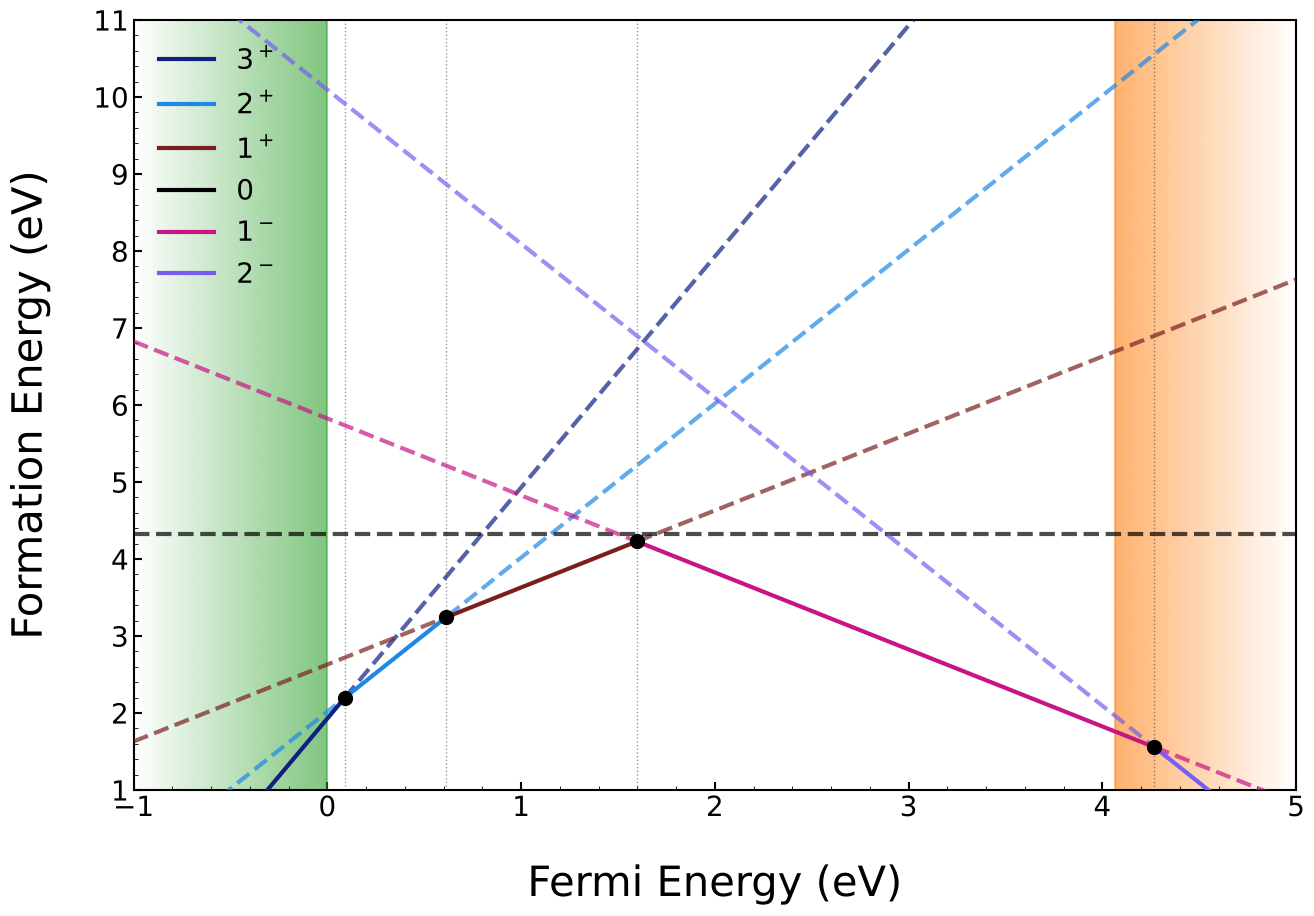

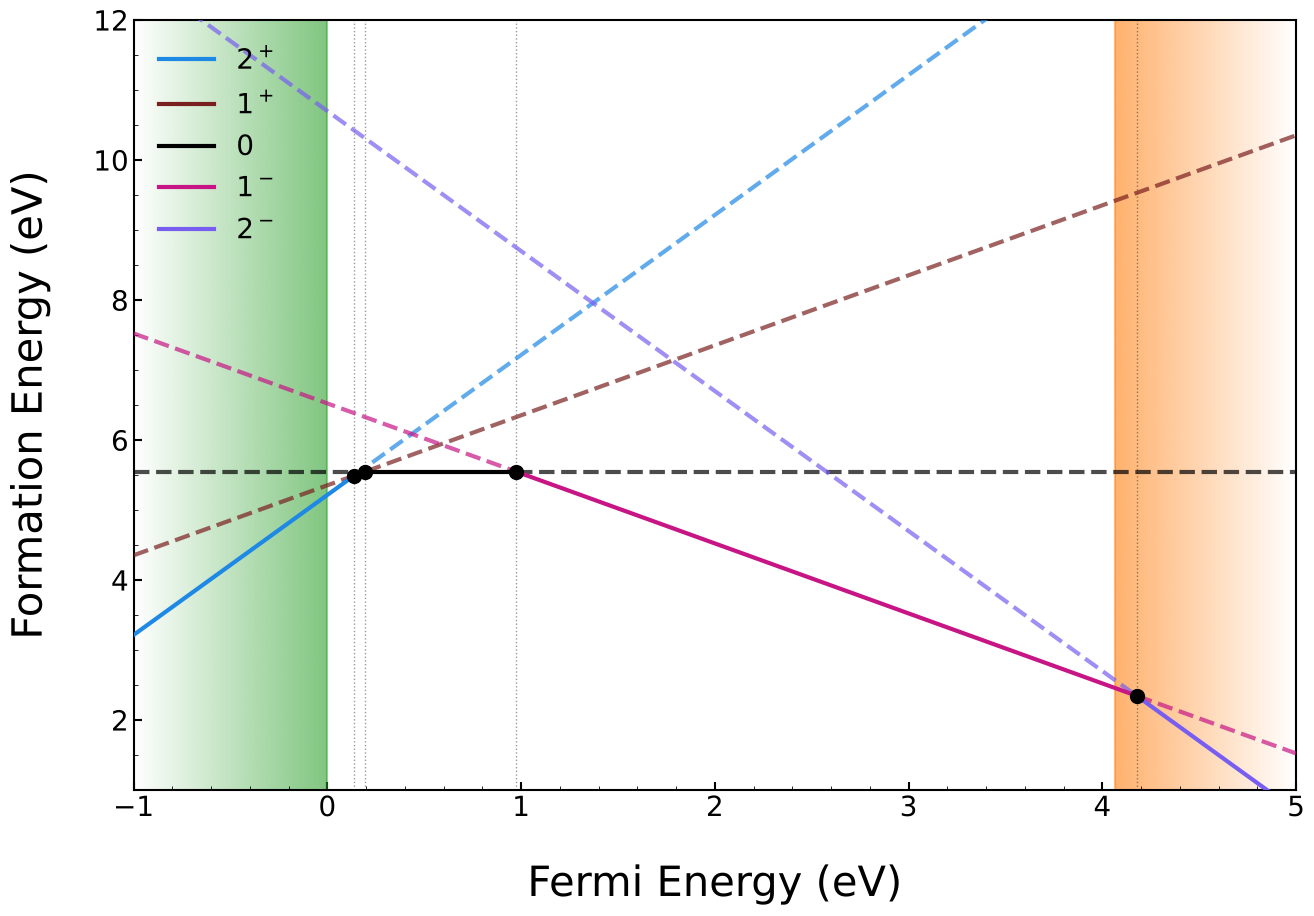

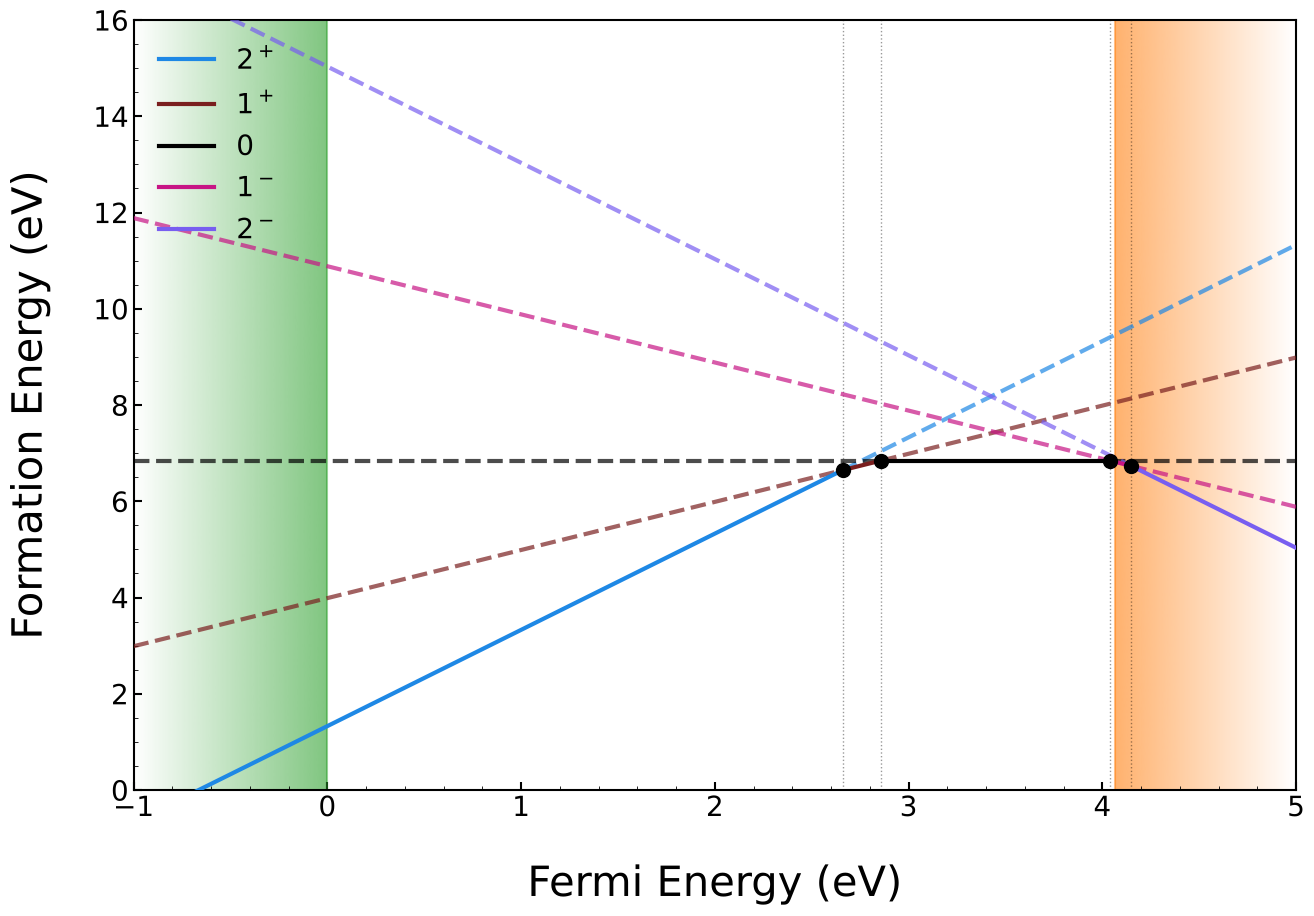

In [3]:
results = plot_ctl(defects, bulk, vbm, cbm, save=False, show=True)

## 3. Reading the transition levels

`plot_ctl` returns a dict keyed by `label`. Each entry holds the matplotlib `figure` and the list of `transitions`.

`E_fermi` is relative to the VBM (eV) and `E_form` is the formation energy at the crossing.
- `kind='thermo'` is a true thermodynamic transition level, plotted as a dot.
- When a transition skips a charge state (negative-U behaviour, e.g. `(1+/1-)`), the transitions *through* the skipped state are also listed with `kind='bypassed'`. They are not drawn in `plot_ctl`, but `plot_multi_mat_ctl` can show them.

In [4]:
for label, res in results.items():
    print(label)
    for t in res['transitions']:
        print(f"   {t['transition']:>10}  E_F = {t['E_fermi']:6.2f} eV   E_form = {t['E_form']:6.2f} eV   ({t['kind']})")

N_i
      (3+/2+)  E_F =   0.09 eV   E_form =   2.20 eV   (thermo)
      (2+/1+)  E_F =   0.61 eV   E_form =   3.24 eV   (thermo)
      (1+/1-)  E_F =   1.60 eV   E_form =   4.23 eV   (thermo)
       (1+/0)  E_F =   1.69 eV   E_form =   4.32 eV   (bypassed)
       (0/1-)  E_F =   1.50 eV   E_form =   4.32 eV   (bypassed)
      (1-/2-)  E_F =   4.27 eV   E_form =   1.56 eV   (thermo)
N_O3c
      (2+/1+)  E_F =   0.14 eV   E_form =   5.49 eV   (thermo)
       (1+/0)  E_F =   0.20 eV   E_form =   5.55 eV   (thermo)
       (0/1-)  E_F =   0.98 eV   E_form =   5.55 eV   (thermo)
      (1-/2-)  E_F =   4.18 eV   E_form =   2.35 eV   (thermo)
V_O3c
      (2+/1+)  E_F =   2.66 eV   E_form =   6.65 eV   (thermo)
       (1+/0)  E_F =   2.86 eV   E_form =   6.85 eV   (thermo)
       (0/1-)  E_F =   4.04 eV   E_form =   6.85 eV   (thermo)
      (1-/2-)  E_F =   4.15 eV   E_form =   6.74 eV   (thermo)


## 4. Styling with `StyleOptions`

All plotting functions accept a `StyleOptions` object, so one style can be reused across plots. The options most relevant to `plot_ctl`:

| option | default | |
|---|---|---|
| `show_title` / `title` | `False` / `None` | draw a title (defaults to `'<title or label> Charge Levels'`) |
| `xlim`, `ylim` | `None` | axis limits (auto by default) |
| `band_alpha` | `0.6` | opacity of the VB/CB shading |
| `axes_fontsize`, `ticks_fontsize` | `30`, `20` | |
| `show_transitions` | `True` | dots + guides at each transition level |
| `show_transition_labels` | `False` | write ε(q/q') under each transition |
| `ctl_label_fontsize` | `20` | |
| `legend_loc`, `legend_frameon`, `legend_fontsize` | `'upper left'`, `False`, `20` | |

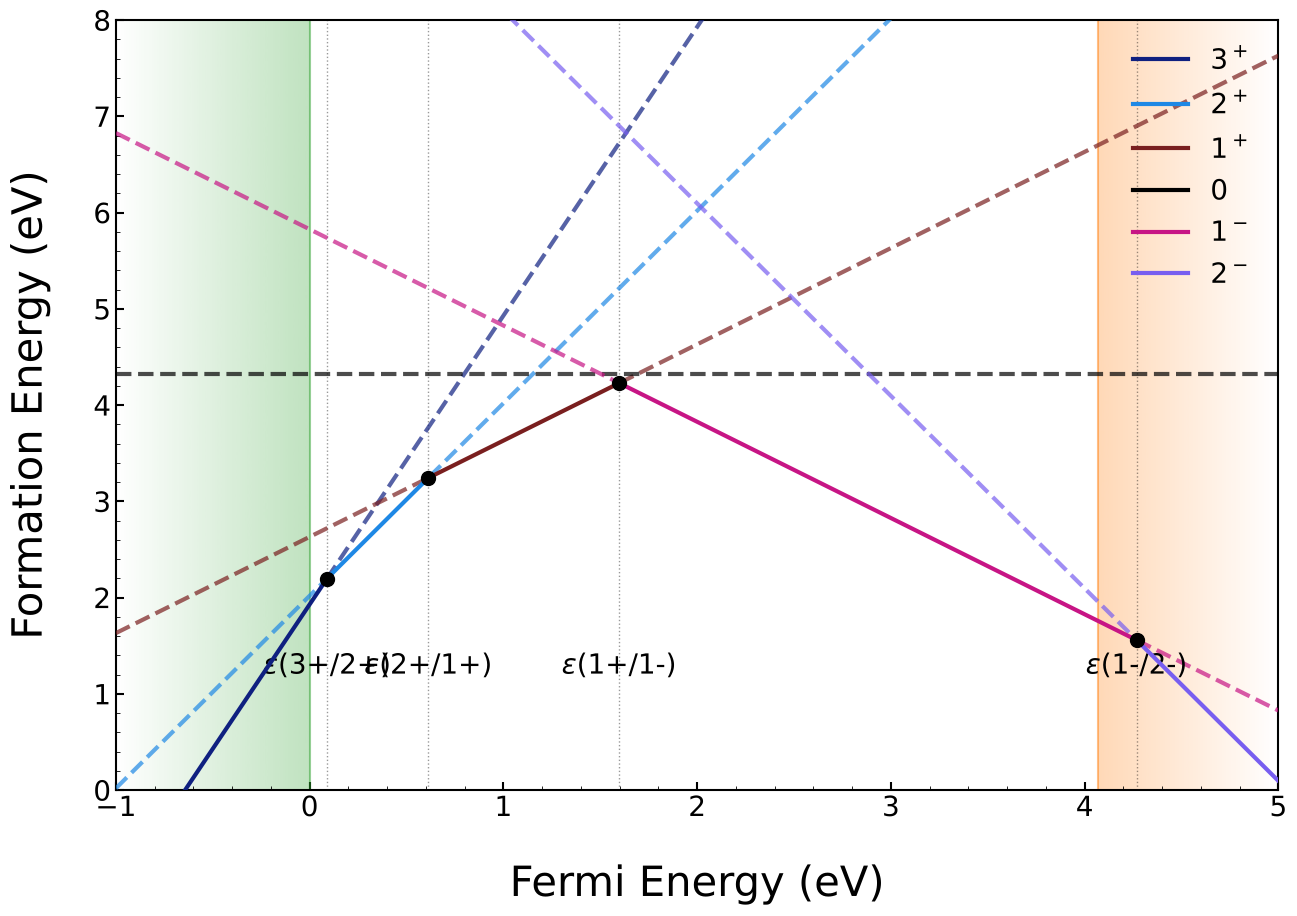

In [5]:
style = StyleOptions(
    show_transition_labels=True,
    ylim=(0, 8),
    band_alpha=0.3,
    legend_loc='upper right',
)

n_i_only = [d for d in defects if d.label == 'N_i']
plot_ctl(n_i_only, bulk, vbm, cbm, style=style, save=False, show=True);

## 5. Loading defects from a CSV

For larger data sets it is easier to keep the defects in a spreadsheet. `load_defects_csv` reads a CSV with a header row and returns a list of `Defect` objects.

- Required columns: `name, charge, energy, mu_added, correction, defect_type, site, mu_removed, label`
- Optional columns: `title, cell_id, site_id, material` (used by the amorphous / multi-material functions)

`write_sample_csv` writes a small template to start from.

In [6]:
write_sample_csv('sample_defects.csv')
print(open('sample_defects.csv').read())

loaded = load_defects_csv('sample_defects.csv')
loaded[0]

name,charge,energy,mu_added,correction,defect_type,site,mu_removed,label,title,cell_id,site_id,material
N,1,-100.5,0.5,0.1,i,,0.0,N_i,N$_i$,cellA,siteA,HfO2
N,0,-100.8,0.5,0.0,i,,0.0,N_i,N$_i$,cellA,siteA,HfO2
N,-1,-101.0,0.5,0.1,i,,0.0,N_i,N$_i$,cellA,siteA,HfO2



Defect(name='N', charge=1, energy=-100.5, mu_added=0.5, correction=0.1, defect_type='i', site='', mu_removed=0.0, label='N_i', title='N$_i$', cell_id='cellA', site_id='siteA', material='HfO2')

In [7]:
import os
os.remove('sample_defects.csv')